Following noteboook is adapted from UnEye code found on github: https://github.com/berenslab/uneye
Please follow instructions on the uneye github repo to set up code and uneye conda environemnt for model training and evaluation. 
This notebook provides a walkthrough for training the joint model whose output was refined in Facemap software and used for saccade-related analyses.

In [4]:
# Set base folder
import sys, os
BASE_FOLDER = os.getcwd().replace('/analysis/notebooks', '')  # Set relative to eye-vs-face repo
print("Base folder set to:", BASE_FOLDER)
UNEYE_FOLDER = f'/media/Atika/eye_movement_paper/pupil_analysis/uneye'  # Set path to UnEye repo
sys.path.append(UNEYE_FOLDER)  # Add UnEye to path

Base folder set to: /home/asyeda/stringerlab_dm11/eye-vs-face


# U'n'Eye: Convolutional Neural Network for eye movement detection

Call the model with uneye.DNN(sampfreq) and then run training / testing / prediction with the method model.train(), model.test() or model.predict(), respectively.

Optional input arguments when calling uneye.DNN() are:
- min_sacc_dur: minimum saccade duration (in ms) for removal of small saccades (post-processing), default: 1==no removal
- min_sacc_dist: minimum distance (in ms) between two saccades for merging of close-by saccades, default: 1==no merge
- weights_name: filename for storage of trained weights. All trained weights will automatically be safed in the local folder 'training'. The default filename is 'weights'
- augmentation: True or False. Whether data augmentation (rotation of signal) should be used. The default is 'True'.
- ks: kernel size of convolutional layers. Has to be odd. Default: 5
- mp: size of max pooling window. Has to be odd. Default: 5
- inf_correction: Float value to replace infs or NaNs in differentiated input data (i.e. eye velocity). Should correspond to maximum value that is expected. Default: 1.5
- val_samples: Number of trials used for validating when to stop training early. Default: 30

### Setup

In [5]:
import numpy as np
import uneye
import os, sys
sys.path.append(f'{BASE_FOLDER}/analysis/code/')
import nonlinear_modelv3
import helper_functions
import pupil_dark_helpers as pdh
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat

In [2]:
##################################
########### Parameters ###########
min_sacc_dur = 1 #minimum saccade duration in ms
min_sacc_dist = 1 #minimum saccade distance in ms

In [3]:
# Function to create sequences from input data
def create_sequences(data, targets, sequence_length=1000, padding=50):
    """
    Create sequences of input data and corresponding targets.
    """
    sequences = []
    target_sequences = []
    indices = []
    seq_start = 0
    seq_end = sequence_length
    while seq_end < len(data):
        indices.append(np.arange(seq_start, seq_end))
        sequences.append(data[seq_start:seq_end])
        target_sequences.append(targets[seq_start:seq_end])
        seq_start += sequence_length + padding
        seq_end += sequence_length + padding
    
    return np.array(sequences), np.array(target_sequences), np.array(indices)

def get_performance_metrics(prediction, ground_truth):
    """
    Calculate performance metrics: accuracy, precision, recall, f1-score.
    Computed for saccade only i.e. prediction == 1.
    Args:
        prediction (np.ndarray): Predicted labels.
        ground_truth (np.ndarray): True labels.
    Returns:
        tuple: (accuracy, precision, recall, f1_score)
    """
    TP = np.sum((prediction == 1) & (ground_truth == 1))
    FP = np.sum((prediction == 1) & (ground_truth == 0))
    FN = np.sum((prediction == 0) & (ground_truth == 1))
    
    accuracy = np.mean(prediction == ground_truth)
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return accuracy, precision, recall, f1_score

def create_sequences_around_labels(data, targets, sequence_length=200):
    """
    Create sequences of input data centered around label indices.
    """
    sequences = []
    target_sequences = []
    indices = []

    # Get start and end indices of saccades based on when diff(targets) changes
    diff_targets = np.diff(targets)
    start_indices = np.where(diff_targets == 1)[0] + 1  # Start of saccade
    # Remove sequences that are too close together to avoid overlapping
    diff_over = np.append(np.diff(start_indices)>sequence_length, True)
    start_indices = start_indices[diff_over]

    for i in range(len(start_indices)):
        start_idx = start_indices[i] - sequence_length//2
        end_idx = start_indices[i] + sequence_length//2
        # Ensure indices are within bounds
        start_idx = max(0, start_idx)
        end_idx = min(len(data), end_idx)
        # Skip if the sequence is too short
        if end_idx - start_idx < sequence_length:
            continue
        sequences.append(data[start_idx:end_idx])
        target_sequences.append(targets[start_idx:end_idx])
        indices.append(np.arange(start_idx, end_idx))
    
    return np.array(sequences), np.array(target_sequences), np.array(indices)

# Training: Training a fine-tuned model using saccade labels from 2 mice
Pre-requisite: follow instructions on the uneye github repo to generate predictions for a dataset using Andersson weights. The output of that model was refined then used for training as follows:
1. Output of model using Andersson weights were used to obtain saccade labels
2. Output labels were refined in Facemap software
3. A new fine-tuned model was trained to generate saccade predictions for remaining mice (light recordings only)
Note: skip to prediction section to generate saccade labels using the fine-tuned model weights on a new mouse data.

In [ ]:
recording_type = "static"

In [ ]:
mouse_list = ['TX140', 'TX143']
blocks_index_selected = [1, 1]
sequence_length = 1000
padding = 25

X_list, Y_list, L_list, data_list = [], [], [], []

for mname in mouse_list:
    db = pdh.carbachol_in_dark() # pdh.get_light_static_info()
    datexp = [entry['datexp'] for entry in db if entry['mname'] == mname][0]

    _, _, _, _, _, _, _, npz_data = nonlinear_modelv3.load_data(f'{BASE_FOLDER}data/npz_data/', mname, datexp)

    pupil_x = npz_data["pupil_x_small"]
    pupil_y = npz_data["pupil_y_small"] 
    block_frames = npz_data['cam_frames_list']
    blk_idx = [blocks_index_selected[mouse_list.index(mname)]]  # use first block only for static and random recordings

    pupil_xy_input = []
    for blk in blk_idx:
        pupil_x_blk = helper_functions.segment_data(pupil_x, block_frames, blk)
        pupil_y_blk = helper_functions.segment_data(pupil_y, block_frames, blk)
        pupil_xy_blk = np.vstack((pupil_x_blk, pupil_y_blk)).T
        pupil_xy_input.append(pupil_xy_blk)

    pupil_xy_input = np.vstack(pupil_xy_input)
    input_data = pupil_xy_input.copy()

    # Get output data
    blk = [entry['blk'] for entry in db if entry['mname'] == mname][blocks_index_selected[mouse_list.index(mname)]]
    labels_file = f"{BASE_FOLDER}data/saccade_labels/{mname}_{datexp}_{blk}_finetuned_model_labels.mat"
    labels = loadmat(labels_file)['eye_movement_data']['Saccade'][0,0].squeeze()

    if labels.shape[0] < input_data.shape[0]:
        input_data = input_data[:labels.shape[0], :]

    # Create sequences
    input_sequences, target_sequences, data_indices = create_sequences(input_data, labels, sequence_length=sequence_length, padding=padding)

    X_list.append(input_sequences[:, :, 0])  # pupil_x sequences
    Y_list.append(input_sequences[:, :, 1])  # pupil_y sequences
    L_list.append(target_sequences)
    data_list.append(data_indices)  # store data indices for reference

# Stack everything into final arrays
X = np.vstack(X_list)  # shape: (num_sequences_total, sequence_length)
Y = np.vstack(Y_list)
L = np.vstack(L_list)  
data_indices = np.vstack(data_list)  # shape: (num_sequences_total, sequence_length)

Sessions from carbachol_in_dark >>>
Sessions from carbachol_in_dark >>>


In [7]:
ntrain = int(0.8*X.shape[0]) # number of samples for training
print("Train samples: ", ntrain, " Test samples: ", X.shape[0]-ntrain)

# Get random subset for training and test
np.random.seed(42)  # for reproducibility
randind = np.random.permutation(X.shape[0])
train_indices = randind[:ntrain]  # first ntrain indices for training
# Ensure indices are unique and not overlapping
test_indices = randind[ntrain:]  # remaining indices for testing
# Split data into training and test sets
Xtrain = X[train_indices,]
Ytrain = Y[train_indices,]
Ltrain = L[train_indices,]
# reduce data to subset that wasn't used for training (only needed for this example)
Xtest = X[test_indices,]
Ytest = Y[test_indices,]
Ltest = L[test_indices,]

Train samples:  90  Test samples:  23


In [ ]:
# fit model on training data
# weights will automatically be saved to local folder 'training'
# call model with optional arguments
lr = 1e-4
sampfreq = 50
weights_name = 'weights_Andersson_finetuned_joint'
base_model_weights =  '/home/asyeda/pupil_analysis/uneye/training/weights_Andersson'

model = uneye.DNN(sampfreq=sampfreq, weights_name=weights_name, finetune_weights=base_model_weights, classes=5, lr=lr)
#model.crossvalidate(Xtrain, Xtrain, Ltrain, Xtest, Ytest, Ltest, K=5)
model.train(Xtrain,Ytrain,Ltrain)

Number of classes: 5
Using GPU: True
30
Loading pretrained weights from /home/asyeda/pupil_analysis/uneye/training/weights_Andersson
Training. Please wait.
Early stopping at epoch 60 before overfitting occurred.
Model parameters saved to ./training/weights_Andersson_finetuned_joint_dark


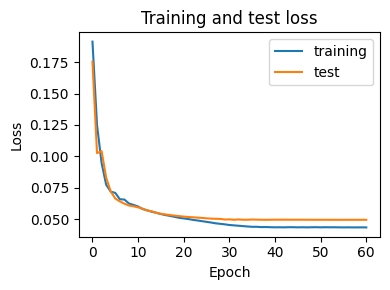

In [9]:
f = plt.figure(figsize=(4,3))
plt.plot(model.loss_train,label='training')
plt.plot(model.loss_val,label='test')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and test loss')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Get all test data predictions
Prediction, Probability, Performance = model.test(Xtest, Ytest, Ltest)

Loading weights from ./training/weights_Andersson_finetuned_joint_dark
Cohens Kappa class 0 :  0.68
Cohens Kappa class 1 :  0.682
Cohens Kappa class 2 :  0.0
Cohens Kappa class 3 :  nan
Cohens Kappa class 4 :  nan
F1: 0.753


/home/asyeda/pupil_analysis/uneye/uneye/classifier.py:518: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  w = torch.load(w_name)
/home/asyeda/anaconda3/envs/saccade/lib/pytho

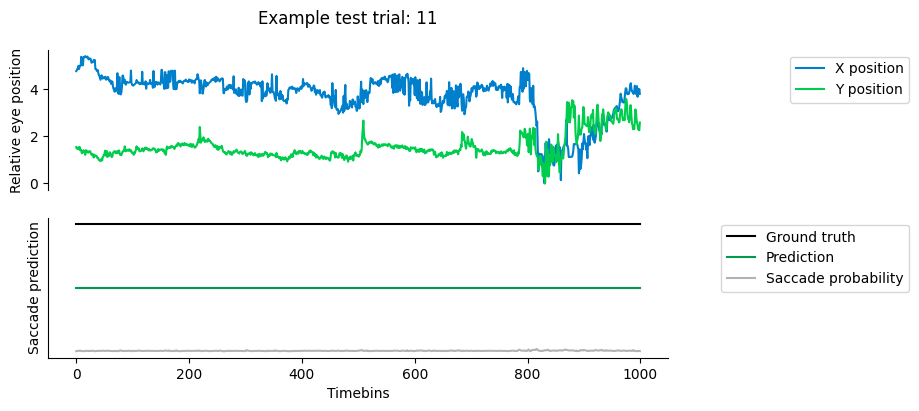

In [19]:
# plot example
i = np.random.randint(Xtest.shape[0])
fig = plt.figure(figsize=(8,4))
plt.suptitle('Example test trial: ' + str(i))
ax = fig.add_subplot(211)
x_trace = Xtest[i,:] - np.min(Xtest[i,:])
y_trace = Ytest[i,:] - np.min(Ytest[i,:])
plt.plot(x_trace,label='X position',c=[0,0.5,0.8])
plt.plot(y_trace,label='Y position',c=[0,0.8,0.3])
plt.xticks(())
plt.ylabel('Relative eye position')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.legend(bbox_to_anchor=(1.4,1))

# prediction
ax = fig.add_subplot(212)
plt.plot(Ltest[i,:]+2.4,label='Ground truth',c='k')
plt.plot(Prediction[i,:]+1.2,label='Prediction',c=[0,0.6,0.3])
plt.plot(Probability[i,1],label='Saccade probability',c='k',alpha=.3)
plt.yticks(())
plt.ylabel('Saccade prediction')
plt.xlabel('Timebins')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(bbox_to_anchor=(1.4,1))

plt.show()

# Prediction: Saccade prediction with finetuned network
Following code used to generate saccades for new mouse videos using the finetuned model weights. Subsequently, the saccades were refined in Facemap software.

In [ ]:
mname = 'FXa1'
blk = '1'
db = pdh.get_light_static_info() 
datexp = [entry['datexp'] for entry in db if entry['mname'] == mname][0]
db

Sessions from get_light_static_info >>>


array([{'sess#': 1, 'mname': 'TX143', 'datexp': '2024_10_28', 'blk': '1', 'blink_baselined_threshold': '1.5', 'speed_threshold': '99.5'},
       {'sess#': 2, 'mname': 'TX143', 'datexp': '2024_10_28', 'blk': '3'},
       {'sess#': 1, 'mname': 'TX139', 'datexp': '2024_10_31', 'blk': '1', 'blink_baselined_threshold': '.2', 'speed_threshold': '99.5'},
       {'sess#': 2, 'mname': 'TX139', 'datexp': '2024_10_31', 'blk': '2'},
       {'sess#': 1, 'mname': 'LZ16', 'datexp': '2024_11_04', 'blk': '1', 'blink_baselined_threshold': '.2', 'speed_threshold': '99.9'},
       {'sess#': 2, 'mname': 'LZ16', 'datexp': '2024_11_04', 'blk': '2'},
       {'sess#': 1, 'mname': 'TX140', 'datexp': '2024_11_06', 'blk': '1', 'blink_baselined_threshold': '.1', 'speed_threshold': '99.5'},
       {'sess#': 2, 'mname': 'TX140', 'datexp': '2024_11_06', 'blk': '2'},
       {'sess#': 1, 'mname': 'FXa1', 'datexp': '2026_01_15', 'blk': '1', 'blink_baselined_threshold': '.1', 'speed_threshold': '99.5'},
       {'sess#': 

In [ ]:
_, _, _, _, _, _, _, npz_data = nonlinear_modelv3.load_data(f'{BASE_FOLDER}data/npz_data/', mname, datexp)

pupil_x = npz_data["pupil_x_small"]
pupil_y = npz_data["pupil_y_small"] 
block_frames = npz_data['cam_frames_list']
blocks = [entry['blk'] for entry in db if entry['mname'] == mname]
blk_idx = [blocks.index(str(blk))]

pupil_xy_input = []
for bki in blk_idx:
    pupil_x_blk = helper_functions.segment_data(pupil_x, block_frames, bki)
    pupil_y_blk = helper_functions.segment_data(pupil_y, block_frames, bki)
    pupil_xy_blk = np.vstack((pupil_x_blk, pupil_y_blk)).T
    pupil_xy_input.append(pupil_xy_blk)
    print(bki)
pupil_xy_input = np.vstack(pupil_xy_input)
input_data = pupil_xy_input.copy()

# Create labels 
labels = np.zeros(input_data.shape[0], dtype=int)  # Initialize labels to 0

# Create sequences
sequence_length = 500  # can change this
padding = 0
input_sequences, target_sequences, _ = create_sequences(input_data, labels, sequence_length, padding)

Xtest = input_sequences[:, :, 0]
Ytest = input_sequences[:, :, 1]
Ltest = target_sequences

pupil_timestamp = npz_data['tcam'].item()['blk'+blk]
cutoff_freq = 1.5  # Adjust this value depending on the movement frequency you want to filter out (in Hz)
tmin = np.min(pupil_timestamp)
cam_time = (pupil_timestamp - tmin) * 24 * 60 * 60
sampfreq = (1 / np.mean(np.diff(cam_time))).astype(int)
print("Sampling frequency:", sampfreq)

0
Sampling frequency: 49


In [ ]:
import uneye
# Prediction
model = uneye.DNN(weights_name='weights/weights_Andersson_finetuned_joint', # path to model finetuned model weights
                 sampfreq=sampfreq,
                 min_sacc_dur=min_sacc_dur,
                min_sacc_dist=min_sacc_dist)
Prediction, Probability = model.predict(Xtest, Ytest)

Loading weights from ./training/weights_Andersson_finetuned_joint


/media/Atika/eye_movement_paper/pupil_analysis/uneye/uneye/classifier.py:386: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  w = torch.load(w_name)


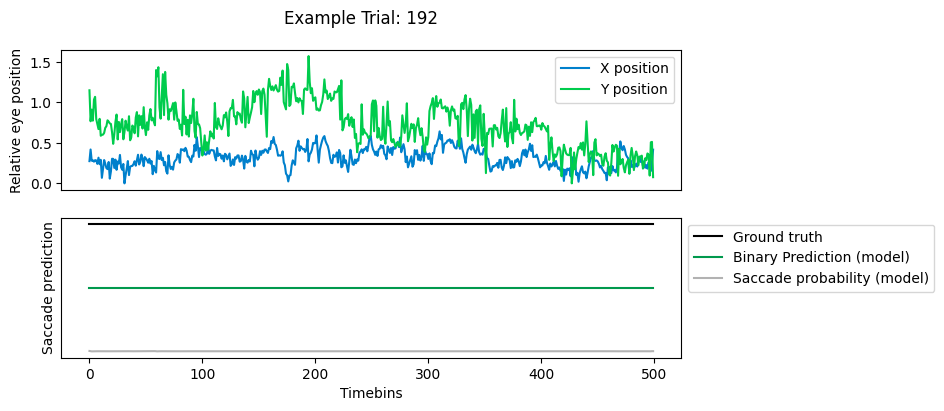

In [8]:
import matplotlib.pyplot as plt
# plot example
i =  np.random.randint(Xtest.shape[0])
fig = plt.figure(figsize=(8,4))
plt.suptitle('Example Trial: ' + str(i))
ax = fig.add_subplot(211)
x_trace = Xtest[i,:] - np.min(Xtest[i,:])
y_trace = Ytest[i,:] - np.min(Ytest[i,:])
plt.plot(x_trace,label='X position',c=[0,0.5,0.8])
plt.plot(y_trace,label='Y position',c=[0,0.8,0.3])
plt.xticks(())
plt.ylabel('Relative eye position')
plt.legend(bbox_to_anchor=(1.,1))

# prediction
ax = fig.add_subplot(212)
plt.plot(Ltest[i,:]+2.4,label='Ground truth',c='k')
plt.plot(Prediction[i,:]+1.2,label='Binary Prediction (model)',c=[0,0.6,0.3])
plt.plot(Probability[i,1,:],label='Saccade probability (model)',c='k',alpha=.3)
#plt.yticks((0,1),['Fix','Sacc'])
plt.yticks([])
plt.ylabel('Saccade prediction')
plt.xlabel('Timebins')
plt.legend(bbox_to_anchor=(1.,1))
plt.show()

In [9]:
Prediction = Prediction.flatten()
Probability = Probability[:, 1,:].flatten()
# replace any values in Prediction that are >1 with 0 to remove other classes
Prediction[Prediction > 1] = 0

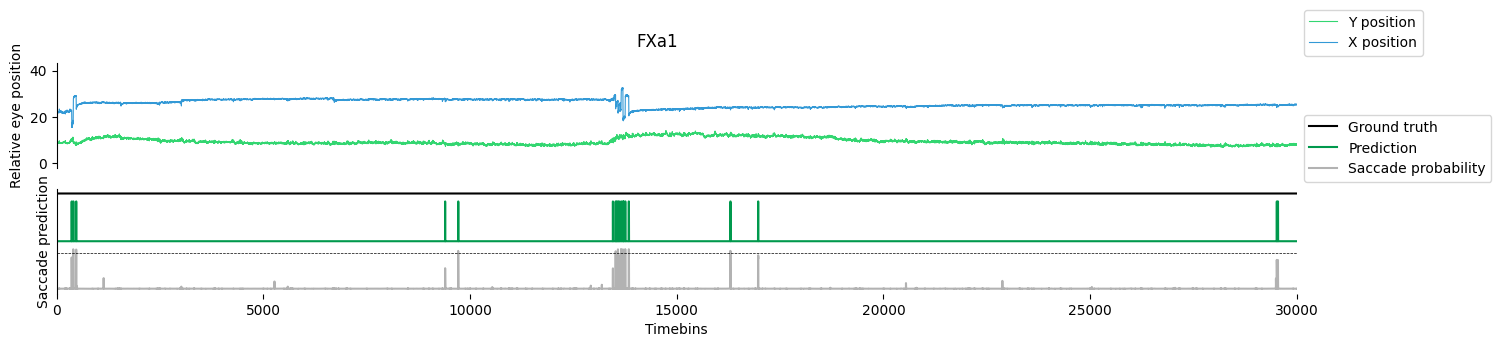

In [ ]:
fig = plt.figure(figsize=(16,3))
xlim = [0, 30000]

%matplotlib inline
ax = fig.add_subplot(211)
x_trace = Xtest.flatten() - np.min(Xtest.flatten())
y_trace = Ytest.flatten() - np.min(Ytest.flatten())
plt.plot(y_trace,label='Y position',c=[0,0.8,0.3], lw=.8, alpha=0.8)
plt.plot(x_trace,label='X position',c=[0,0.5,0.8], lw=.8, alpha=0.8)
plt.xticks(())
plt.ylabel('Relative eye position')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlim(xlim)
#ax.set_ylim([0,10])
plt.legend(bbox_to_anchor=(1.,1))

ax = fig.add_subplot(212)
plt.plot(Ltest.flatten()+2.4,label='Ground truth',c='k')
plt.plot(Prediction+1.2,label='Prediction',c=[0,0.6,0.3])
plt.plot(Probability,label='Saccade probability',c='k',alpha=.3)
plt.yticks((0,1),['Fix','Sacc'])
plt.hlines(.9,0,Probability.shape[0],linestyle='--',color='k', lw=.5)
plt.yticks(())
plt.ylabel('Saccade prediction')
plt.xlabel('Timebins')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_xlim(xlim)
plt.legend(bbox_to_anchor=(1.,1))

fig.suptitle(mname)
plt.show()

In [11]:
from scipy import signal

def butter_lowpass_filter(data, cutoff_freq, sampling_rate, order=5):
    # Nyquist frequency
    nyquist = 0.5 * sampling_rate
    # Normalized cutoff frequency (as a fraction of Nyquist frequency)
    normal_cutoff = cutoff_freq / nyquist
    
    # Design the Butterworth filter
    b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    # Apply the filter to the data
    filtered_data = signal.filtfilt(b, a, data)
    return filtered_data


# Plot peak velocity vs saccade amplitude
x_trace = Xtest.flatten() 
y_trace = Ytest.flatten()

#x_trace = butter_lowpass_filter(x_trace, 1.5, sampfreq)3
#y_trace = butter_lowpass_filter(y_trace, 1.5, sampfreq)

# Compute velocity
vel_x = np.diff(x_trace) #* sampfreq  # velocity in x
vel_y = np.diff(y_trace) #* sampfreq  # velocity in y
vel = np.sqrt(vel_x**2 + vel_y**2)
# Compute amplitude (displacement from start)
amp = np.sqrt((x_trace - x_trace[0])**2 + (y_trace - y_trace[0])**2)

Text(0.5, 1.0, 'FXa1: Saccade Amplitude vs Peak Velocity')

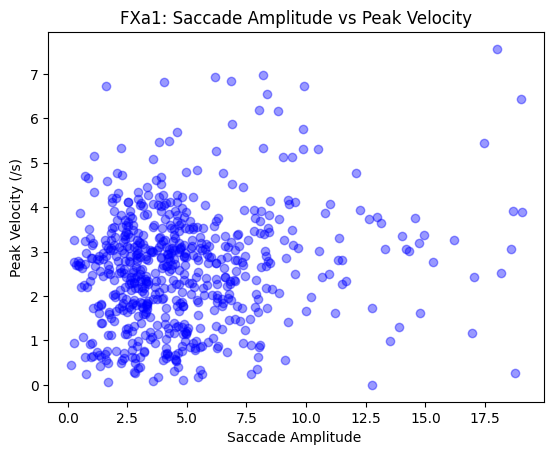

In [12]:
# Get saccade start and end indices and plot the peak velocity and amplitude
sac_start_indices = np.where(np.diff(Prediction) == 1)[0] + 1  # Start of saccade
sac_end_indices = np.where(np.diff(Prediction) == -1)[0] + 1  # End of saccade

for sac in range(len(sac_start_indices)):
    start_idx = sac_start_indices[sac]
    end_idx = sac_end_indices[sac] if sac < len(sac_end_indices) else len(vel)  # Handle last saccade
    peak_velocity = np.max(vel[start_idx:end_idx])
    peak_velocity_idx = np.argmax(vel[start_idx:end_idx]) + start_idx  # Index of peak velocity in the segment
    amplitude = amp[peak_velocity_idx]  # Amplitude at the peak velocity index
    plt.scatter(amplitude, peak_velocity, color='blue', alpha=0.4)
plt.xlabel('Saccade Amplitude ')
plt.ylabel('Peak Velocity (/s)')
plt.title(f'{mname}: Saccade Amplitude vs Peak Velocity')
#plt.xlim(0, np.max(amp) * 1.1)
#plt.ylim(0, 50)

In [ ]:
# Ensure all variables are of type double and proper shape
X = np.asarray(pupil_x_blk, dtype=np.float64).reshape(-1, 1)
Y = np.asarray(pupil_y_blk, dtype=np.float64).reshape(-1, 1)
Saccade = np.asarray(Prediction, dtype=np.float64).reshape(-1, 1)  # Convert to double
Frequency = np.array([[sampfreq]], dtype=np.float64)  # shape (1, 1)

# Make sure prediction is of same length as X and Y. If not, add zeros at the end
if X.shape[0] != Saccade.shape[0] and Saccade.shape[0] < X.shape[0]:
    pad_length = X.shape[0] - Saccade.shape[0]
    padding = [(0, pad_length)] + [(0, 0) for _ in range(Saccade.ndim - 1)]  # No padding for other dimensions
    Saccade = np.pad(Saccade, padding, mode='constant', constant_values=0)
if X.shape[0] != Probability.shape[0] and Probability.shape[0] < X.shape[0]:
    # pad with zeros if necessary
    pad_length = X.shape[0] - Probability.shape[0]
    padding = [(0, pad_length)] + [(0, 0) for _ in range(Probability.ndim - 1)]  # No padding for other dimensions
    Probability = np.pad(Probability, padding, mode='constant', constant_values=0)
# Bundle into MATLAB-compatible struct
if os.path.exists(f'{BASE_FOLDER}data/saccade_labels/{mname}_{datexp}_{blk}_saccade_labels.mat'):
    eye_movement_data_loaded = loadmat(f'{BASE_FOLDER}data/saccade_labels/{mname}_{datexp}_{blk}_saccade_labels.mat')['eye_movement_data']
    SaccadeReference = eye_movement_data_loaded['SaccadeReference']
    print("Copied old SaccadeReference")
else:
    SaccadeReference = Saccade
    print("Created new SaccadeReference")

eye_movement_data = {
    'X': X,
    'Y': Y,
    'Frequency': Frequency,
    'Saccade': Saccade,
    'SaccadeReference': SaccadeReference,
    'Probability': np.asarray(Probability, dtype=np.float64).reshape(-1, 1)  # Convert to double
}


Created new SaccadeReference


In [ ]:
print("Saving to file:", f'{BASE_FOLDER}data/saccade_labels/{mname}_{datexp}_{blk}_saccade_labels.mat')

Saving to file: /home/asyeda/nas113/Atika//FXa1/2026_01_15/1/finetuned_labels/FXa1_2026_01_15_1_saccade_labels.mat


In [ ]:
# Save to .mat file
# check if dir exists; otherwise create it
if not os.path.exists(f'{BASE_FOLDER}data/saccade_labels/{mname}/{datexp}/{blk}/finetuned_labels/'):
    os.makedirs(f'{BASE_FOLDER}data/saccade_labels/{mname}/{datexp}/{blk}/finetuned_labels/')
savemat(f'{BASE_FOLDER}data/saccade_labels/{mname}/{datexp}/{blk}/finetuned_labels/{mname}_{datexp}_{blk}_saccade_labels.mat', {
    'eye_movement_data': eye_movement_data
})

Next, open the file in Facemap to load and visualize saccade events with mouse video.